# 01 — EDA: IBM Telco Customer Churn (EXTENDED)

**Mục đích:** đo số liệu thật trên dataset trước khi amplify, và chốt các quyết định dữ liệu cho W2–W3.

| Thông tin | Giá trị |
|---|---|
| Dataset | `data/raw/telco.csv` — IBM Telco **EXTENDED** |
| Shape kỳ vọng | 7,043 rows × 50 cols |
| `Total Charges` | float64 (không cần cast) |
| `Customer Status` | Churned / Stayed / **Joined** |
| Pipeline | **CLEAN → AMPLIFY → PARTITION** |

**Notebook này trả lời 5 câu hỏi:**

1. Có bao nhiêu dòng `Joined` và churn rate thật sau khi bỏ chúng?
2. Cột nào là leakage? (đo bằng univariate AUC → đây chính là số liệu cho **E0**)
3. Cột nào zero-variance / trùng lặp?
4. Phân phối `Churn Category` ra sao? (chuẩn bị cho **E5.2**)
5. Bảng chốt **29 features** phủ đủ 50 cột gốc.

**Output:** `data/processed/eda_7043.parquet` (D0.5) + bảng quyết định feature.


## 1. Cài đặt môi trường và import thư viện

Import pandas, numpy, matplotlib, seaborn và các hằng số phân loại cột từ `src.data.clean` — **single source of truth** cho danh sách feature/drop.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Make the repo root importable when the notebook runs from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.config import get_config
from src.data.clean import (
    ACCOUNT_COLS,
    CATEGORICAL_COLS,
    CONSTANT_COLS,
    DEMOGRAPHIC_COLS,
    DERIVED_DUP_COLS,
    DROPPED_COLS,
    FEATURE_COLS,
    GEO_COLS,
    ID_COL,
    INDIRECT_POSTHOC_COLS,
    NUMERIC_COLS,
    POSTHOC_DERIVED_COLS,
    SERVICE_COLS,
    STATUS_COL,
    TARGET_COL,
    TARGET_LEAKAGE_COLS,
    USAGE_BILLING_COLS,
    load_raw,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

CFG = get_config()
print(f"repo root      : {REPO_ROOT}")
print(f"raw data       : {CFG.paths.raw_data}")
print(f"expected feats : {CFG.data.expected_feature_count}")
print(f"pandas {pd.__version__} | numpy {np.__version__}")


repo root      : /home/pcn/261/big_data/source
raw data       : /home/pcn/261/big_data/source/data/raw/telco.csv
expected feats : 29
pandas 3.1.1 | numpy 2.5.4


## 2. Đọc dữ liệu đầu vào

Load raw CSV qua `load_raw()` — hàm này đã xử lý 2 cạm bẫy của dataset:

- Header lỗi `"Total Refu    nds"` (4 dấu cách chèn giữa) → được sửa thành `Total Refunds`
- `keep_default_na=False` → chuỗi `"None"` trong `Offer` / `Internet Type` **không** bị biến thành NaN


In [2]:
raw = load_raw()

print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
assert raw.shape == (7043, 50), f"Unexpected shape: {raw.shape}"
print("\nFirst 3 rows (transposed for readability):")
display(raw.head(3).T)


Repaired malformed header(s): {'Total Refu    nds': 'Total Refunds'}


Shape: 7,043 rows x 50 columns

First 3 rows (transposed for readability):


,0,1,2
Customer ID,8779-QRDMV,7495-OOKFY,1658-BYGOY
Gender,Male,Female,Male
Age,78,74,71
Under 30,No,No,No
Senior Citizen,Yes,Yes,Yes
Married,No,Yes,No
Dependents,No,Yes,Yes
Number of Dependents,0,1,3
Country,United States,United States,United States
State,California,California,California


In [3]:
dtype_table = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": [raw[c].iloc[0] for c in raw.columns],
})
print(f"dtype counts: {raw.dtypes.astype(str).value_counts().to_dict()}")
display(dtype_table)


dtype counts: {'str': 31, 'int64': 11, 'float64': 8}


,dtype,n_unique,example
Customer ID,str,7043,8779-QRDMV
Gender,str,2,Male
Age,int64,62,78
Under 30,str,2,No
Senior Citizen,str,2,Yes
Married,str,2,No
Dependents,str,2,No
Number of Dependents,int64,10,0
Country,str,1,United States
State,str,1,California


## 3. Kiểm tra và làm sạch dữ liệu

### 3.1 `Customer Status` — 3 lớp và nhóm `Joined`

Đây là bằng chứng để chốt quyết định: **bỏ `Joined` trước khi amplify**.


In [4]:
status_counts = raw[STATUS_COL].value_counts()
status_pct = (status_counts / len(raw) * 100).round(2)

status_table = pd.DataFrame({
    "count": status_counts,
    "pct": status_pct,
    "churn_label_yes": raw.groupby(STATUS_COL)["Churn Label"].apply(lambda s: (s == "Yes").sum()),
})
display(status_table)

n_joined = int(status_counts.get("Joined", 0))
print(f"\n>>> Joined rows: {n_joined:,} ({n_joined / len(raw) * 100:.2f}% of dataset)")
print(">>> These are dropped BEFORE amplification (no full observation window).")


,count,pct,churn_label_yes
Customer Status,,,
Churned,1869,26.5400,1869
Joined,454,6.4500,0
Stayed,4720,67.0200,0



>>> Joined rows: 454 (6.45% of dataset)
>>> These are dropped BEFORE amplification (no full observation window).


### 3.2 Churn rate — trước và sau khi bỏ `Joined`

Kiểm tra `Churn Label` có khớp 100% với `Customer Status` không (nếu lệch → phải điều tra).


In [5]:
# --- Consistency: Churn Label must agree with Customer Status ---
label_as_int = (raw["Churn Label"] == "Yes").astype(int)
status_as_int = (raw[STATUS_COL] == "Churned").astype(int)
n_mismatch = int((label_as_int != status_as_int).sum())
print(f"Churn Label vs Customer Status mismatches: {n_mismatch}")
assert n_mismatch == 0, "Churn Label and Customer Status disagree — investigate before proceeding"

# --- Churn rate before / after dropping Joined ---
rate_all = label_as_int.mean()
df_no_joined = raw[raw[STATUS_COL] != "Joined"]
rate_clean = (df_no_joined["Churn Label"] == "Yes").mean()

churn_table = pd.DataFrame({
    "cohort": ["all rows (incl. Joined)", "after dropping Joined"],
    "n_rows": [len(raw), len(df_no_joined)],
    "n_churned": [int(label_as_int.sum()), int((df_no_joined["Churn Label"] == "Yes").sum())],
    "churn_rate": [rate_all, rate_clean],
})
display(churn_table)

print(f"\n>>> Churn rate after dropping Joined: {rate_clean:.4f} ({rate_clean*100:.2f}%)")
print(">>> Spec target was ~26.5%; the measured value is the authoritative number.")


Churn Label vs Customer Status mismatches: 0


,cohort,n_rows,n_churned,churn_rate
0,all rows (incl. Joined),7043,1869,0.2654
1,after dropping Joined,6589,1869,0.2837



>>> Churn rate after dropping Joined: 0.2837 (28.37%)
>>> Spec target was ~26.5%; the measured value is the authoritative number.


### 3.3 Missing values & duplicates

Kỳ vọng: NaN chỉ ở `Churn Category` / `Churn Reason` (chỉ có giá trị khi khách đã churn).
`Offer` và `Internet Type` dùng chuỗi `"None"` — **không phải** NaN.


In [6]:
missing = pd.DataFrame({
    "n_missing": raw.isna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(2),
})
missing = missing[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)

print(f"Columns with NaN: {len(missing)}")
display(missing)

# Confirm the "None" sentinel is preserved as a real category
for col in ["Offer", "Internet Type"]:
    vals = raw[col].value_counts(dropna=False)
    has_none_str = "None" in vals.index
    print(f"\n{col}: 'None' present as literal string = {has_none_str}")
    display(vals.to_frame("count"))

# Duplicates
n_dup_rows = int(raw.duplicated().sum())
n_dup_ids = int(raw[ID_COL].duplicated().sum())
print(f"\nDuplicate full rows : {n_dup_rows}")
print(f"Duplicate Customer ID: {n_dup_ids}")
assert n_dup_ids == 0, "Customer ID must be unique"


Columns with NaN: 2


,n_missing,pct_missing
Churn Category,5174,73.4600
Churn Reason,5174,73.4600



Offer: 'None' present as literal string = True


,count
Offer,
None,3877
Offer B,824
Offer E,805
Offer D,602
Offer A,520
Offer C,415



Internet Type: 'None' present as literal string = True


,count
Internet Type,
Fiber Optic,3035
DSL,1652
None,1526
Cable,830



Duplicate full rows : 0
Duplicate Customer ID: 0


### 3.4 Zero-variance check (Loại 4)

Cột chỉ có 1 giá trị duy nhất không mang thông tin và làm CTGAN/copulas mất ổn định.


In [7]:
nunique = raw.nunique()
zero_var = nunique[nunique <= 1]

print(f"Zero-variance columns detected: {len(zero_var)}")
if len(zero_var):
    display(pd.DataFrame({
        "n_unique": zero_var,
        "constant_value": [raw[c].iloc[0] for c in zero_var.index],
    }))

print(f"\nDeclared CONSTANT_COLS (Loại 4): {CONSTANT_COLS}")
assert set(CONSTANT_COLS) <= set(zero_var.index), "A declared constant column is not constant"
print(">>> Confirmed: Country, State, Quarter are single-valued.")

# High-cardinality geographic columns (Loại 5)
geo_card = pd.DataFrame({
    "n_unique": [raw[c].nunique() for c in GEO_COLS],
    "pct_unique": [round(raw[c].nunique() / len(raw) * 100, 2) for c in GEO_COLS],
}, index=GEO_COLS)
print("\nGeographic columns (Loại 5 — EDA only, never features):")
display(geo_card)


Zero-variance columns detected: 3


,n_unique,constant_value
Country,1,United States
State,1,California
Quarter,1,Q3



Declared CONSTANT_COLS (Loại 4): ['Country', 'State', 'Quarter']
>>> Confirmed: Country, State, Quarter are single-valued.

Geographic columns (Loại 5 — EDA only, never features):


,n_unique,pct_unique
City,1106,15.7000
Zip Code,1626,23.0900
Latitude,1626,23.0900
Longitude,1625,23.0700
Population,1569,22.2800


### 3.5 Leakage audit — univariate AUC (số liệu cho **E0**)

Với mỗi cột nghi ngờ leakage, đo AUC khi dùng **một mình cột đó** để dự đoán churn.
AUC ≈ 0.5 = không có tín hiệu; AUC > 0.9 = gần như đọc được nhãn → leakage.

`Churn Score` là baseline ngoài cho **E0**: nó dùng thông tin post-hoc mà model của ta **không được phép** dùng.


In [8]:
y = (df_no_joined["Churn Label"] == "Yes").astype(int).to_numpy()


def univariate_auc(series: pd.Series, target: np.ndarray) -> float:
    """Raw AUC of a single column used directly as a score (numeric only)."""
    values = pd.to_numeric(series, errors="coerce")
    mask = values.notna().to_numpy()
    if mask.sum() < 10 or len(np.unique(values[mask])) < 2:
        return float("nan")
    return float(roc_auc_score(target[mask], values[mask]))


SUSPECT_COLS = [
    "Churn Score",          # Loại 2 — IBM precomputed
    "CLTV",                 # Loại 2
    "Satisfaction Score",   # Loại 2
    "Total Revenue",        # Loại 3
    "Total Refunds",        # Loại 3
]

raw_auc = {c: univariate_auc(df_no_joined[c], y) for c in SUSPECT_COLS}

# AUC < 0.5 means the column is INVERSELY related to churn. Predictive power is
# max(auc, 1-auc); the direction tells us the sign of the effect.
leakage_audit = pd.DataFrame({
    "raw_auc": pd.Series(raw_auc),
    "direction": ["inverse" if v < 0.5 else "direct" for v in raw_auc.values()],
    "predictive_power": [max(v, 1 - v) for v in raw_auc.values()],
}, index=SUSPECT_COLS)
leakage_audit["category"] = (
    ["Loại 2"] * len(POSTHOC_DERIVED_COLS) + ["Loại 3"] * 2
)
leakage_audit = leakage_audit.sort_values("predictive_power", ascending=False)

display(leakage_audit)

e0_auc = float(leakage_audit.loc["Churn Score", "raw_auc"])
print(f"\n>>> E0 REFERENCE: IBM Churn Score univariate AUC = {e0_auc:.4f}")
print(">>> This is the 'unfair ceiling' our models must be compared against.")
print(">>> Churn Score is NEVER a feature — it is the E0 external baseline only.")
print("\n>>> Note: Satisfaction Score / CLTV / Total Revenue are INVERSELY related")
print(">>> to churn (higher satisfaction -> lower churn), hence raw AUC < 0.5.")


,raw_auc,direction,predictive_power,category
Satisfaction Score,0.0506,inverse,0.9494,Loại 2
Churn Score,0.9421,direct,0.9421,Loại 2
Total Revenue,0.2768,inverse,0.7232,Loại 3
CLTV,0.4099,inverse,0.5901,Loại 2
Total Refunds,0.4849,inverse,0.5151,Loại 3



>>> E0 REFERENCE: IBM Churn Score univariate AUC = 0.9421
>>> This is the 'unfair ceiling' our models must be compared against.
>>> Churn Score is NEVER a feature — it is the E0 external baseline only.

>>> Note: Satisfaction Score / CLTV / Total Revenue are INVERSELY related
>>> to churn (higher satisfaction -> lower churn), hence raw AUC < 0.5.


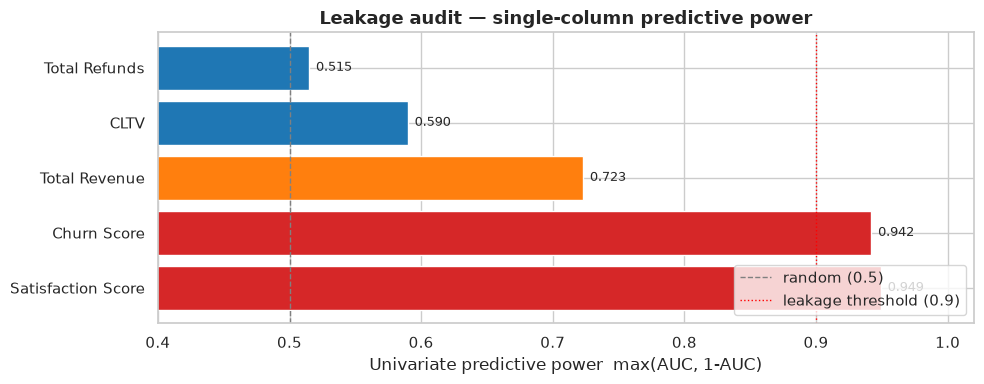

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#d62728" if v > 0.9 else "#ff7f0e" if v > 0.7 else "#1f77b4"
          for v in leakage_audit["predictive_power"]]
bars = ax.barh(leakage_audit.index, leakage_audit["predictive_power"], color=colors)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="random (0.5)")
ax.axvline(0.9, color="red", linestyle=":", linewidth=1, label="leakage threshold (0.9)")
ax.set_xlim(0.4, 1.02)
ax.set_xlabel("Univariate predictive power  max(AUC, 1-AUC)")
ax.set_title("Leakage audit — single-column predictive power")
ax.legend(loc="lower right")
for bar, val in zip(bars, leakage_audit["predictive_power"]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.3f}",
            va="center", fontsize=9)
plt.tight_layout()
plt.show()


### 3.6 Redundancy check (Loại 6)

Ba cặp cột dẫn xuất trùng lặp. Giữ biến **gốc / chi tiết hơn**, bỏ biến nhị phân hoá.

Ngoại lệ: `Number of Referrals` được **giữ** làm feature #29 (patch gốc liệt kê 28 — thiếu cột này).


In [10]:
# --- Pair 1: Under 30  vs  Age ---
under30_expected = (df_no_joined["Age"] < 30).map({True: "Yes", False: "No"})
agree_under30 = (under30_expected == df_no_joined["Under 30"]).mean()

# --- Pair 2: Referred a Friend  vs  Number of Referrals ---
referred_expected = (df_no_joined["Number of Referrals"] > 0).map({True: "Yes", False: "No"})
agree_referred = (referred_expected == df_no_joined["Referred a Friend"]).mean()

# --- Pair 3: Dependents (binary)  vs  Number of Dependents ---
dependents_expected = (df_no_joined["Number of Dependents"] > 0).map({True: "Yes", False: "No"})
agree_dependents = (dependents_expected == df_no_joined["Dependents"]).mean()

redundancy = pd.DataFrame({
    "derived_col": ["Under 30", "Referred a Friend", "Dependents"],
    "source_col": ["Age", "Number of Referrals", "Number of Dependents"],
    "agreement_pct": [agree_under30 * 100, agree_referred * 100, agree_dependents * 100],
    "decision": ["drop derived", "drop derived", "drop derived"],
})
display(redundancy)

print(">>> All three derived columns are deterministic functions of their source.")
print(">>> Keeping the granular source column preserves information.")

# --- Justify keeping Number of Referrals as feature #29 ---
auc_referrals = univariate_auc(df_no_joined["Number of Referrals"], y)
print(f"\nNumber of Referrals univariate AUC = {auc_referrals:.4f}")
print(">>> Non-trivial signal → retained as feature #29 (patch listed only 28).")


,derived_col,source_col,agreement_pct,decision
0,Under 30,Age,100.0000,drop derived
1,Referred a Friend,Number of Referrals,100.0000,drop derived
2,Dependents,Number of Dependents,100.0000,drop derived


>>> All three derived columns are deterministic functions of their source.
>>> Keeping the granular source column preserves information.

Number of Referrals univariate AUC = 0.3420
>>> Non-trivial signal → retained as feature #29 (patch listed only 28).


### 3.7 `Churn Category` — 5 strata cho **E5.2**

Chỉ có giá trị khi khách đã churn. Dùng để stratify fairness analysis ở E5.2.


In [11]:
churn_cat = df_no_joined["Churn Category"].value_counts(dropna=False)
churn_cat_pct = (churn_cat / churn_cat.sum() * 100).round(2)

cat_table = pd.DataFrame({"count": churn_cat, "pct_of_churners": churn_cat_pct})
display(cat_table)

n_strata = df_no_joined["Churn Category"].nunique()
print(f"\n>>> Distinct churn categories: {n_strata}")
print(">>> These become the strata for E5.2 (fairness by churn reason).")

# Top churn reasons within each category
top_reasons = (
    df_no_joined.dropna(subset=["Churn Reason"])
    .groupby(["Churn Category", "Churn Reason"])
    .size()
    .reset_index(name="count")
    .sort_values(["Churn Category", "count"], ascending=[True, False])
    .groupby("Churn Category")
    .head(3)
)
print("\nTop 3 churn reasons per category:")
display(top_reasons)


,count,pct_of_churners
Churn Category,,
NaN,4720,71.6300
Competitor,841,12.7600
Attitude,314,4.7700
Dissatisfaction,303,4.6000
Price,211,3.2000
Other,200,3.0400



>>> Distinct churn categories: 5
>>> These become the strata for E5.2 (fairness by churn reason).

Top 3 churn reasons per category:


,Churn Category,Churn Reason,count
1,Attitude,Attitude of support person,220
0,Attitude,Attitude of service provider,94
2,Competitor,Competitor had better devices,313
3,Competitor,Competitor made better offer,311
5,Competitor,Competitor offered more data,117
11,Dissatisfaction,Product dissatisfaction,77
8,Dissatisfaction,Network reliability,72
12,Dissatisfaction,Service dissatisfaction,63
14,Other,Don't know,130
15,Other,Moved,46


## 4. Thực hiện biến đổi và tính toán chính

### 4.1 Phân phối 29 feature ứng viên

Thống kê mô tả cho numeric, tần suất cho categorical.


In [12]:
print(f"FEATURE_COLS: {len(FEATURE_COLS)} total "
      f"({len(NUMERIC_COLS)} numeric, {len(CATEGORICAL_COLS)} categorical)")
assert len(FEATURE_COLS) == 29

print("\n--- Numeric features: describe() ---")
display(df_no_joined[NUMERIC_COLS].describe().T)

print("\n--- Categorical features: cardinality ---")
cat_card = pd.DataFrame({
    "n_unique": [df_no_joined[c].nunique() for c in CATEGORICAL_COLS],
    "values": [", ".join(map(str, df_no_joined[c].unique()[:6])) for c in CATEGORICAL_COLS],
}, index=CATEGORICAL_COLS)
display(cat_card)


FEATURE_COLS: 29 total (10 numeric, 19 categorical)

--- Numeric features: describe() ---


,count,mean,std,min,25%,50%,75%,max
Age,"6,589.0000",46.7605,16.8414,19.0000,33.0000,46.0000,60.0000,80.0000
Number of Dependents,"6,589.0000",0.4761,0.9685,0.0000,0.0000,0.0000,0.0000,9.0000
Tenure in Months,"6,589.0000",34.4998,23.9687,1.0000,12.0000,32.0000,57.0000,72.0000
Number of Referrals,"6,589.0000",2.0209,3.0240,0.0000,0.0000,0.0000,3.0000,11.0000
Avg Monthly Long Distance Charges,"6,589.0000",23.0043,15.4668,0.0000,9.2500,22.9200,36.4400,49.9900
Avg Monthly GB Download,"6,589.0000",20.8765,20.4062,0.0000,4.0000,17.0000,27.0000,85.0000
Monthly Charge,"6,589.0000",66.2285,29.9074,18.2500,40.5500,72.8500,90.6000,118.7500
Total Charges,"6,589.0000","2,432.0422","2,265.5001",18.8500,544.5500,"1,563.9000","4,003.0000","8,684.8000"
Total Extra Data Charges,"6,589.0000",7.1695,25.8032,0.0000,0.0000,0.0000,0.0000,150.0000
Total Long Distance Charges,"6,589.0000",798.0873,853.7680,0.0000,106.6800,472.6800,"1,275.1200","3,564.7200"



--- Categorical features: cardinality ---


,n_unique,values
Gender,2,"Male, Female"
Senior Citizen,2,"Yes, No"
Married,2,"No, Yes"
Offer,6,"None, Offer E, Offer D, Offer C, Offer B, Offer A"
Contract,3,"Month-to-Month, One Year, Two Year"
Paperless Billing,2,"Yes, No"
Payment Method,3,"Bank Withdrawal, Credit Card, Mailed Check"
Phone Service,2,"No, Yes"
Multiple Lines,2,"No, Yes"
Internet Service,2,"Yes, No"


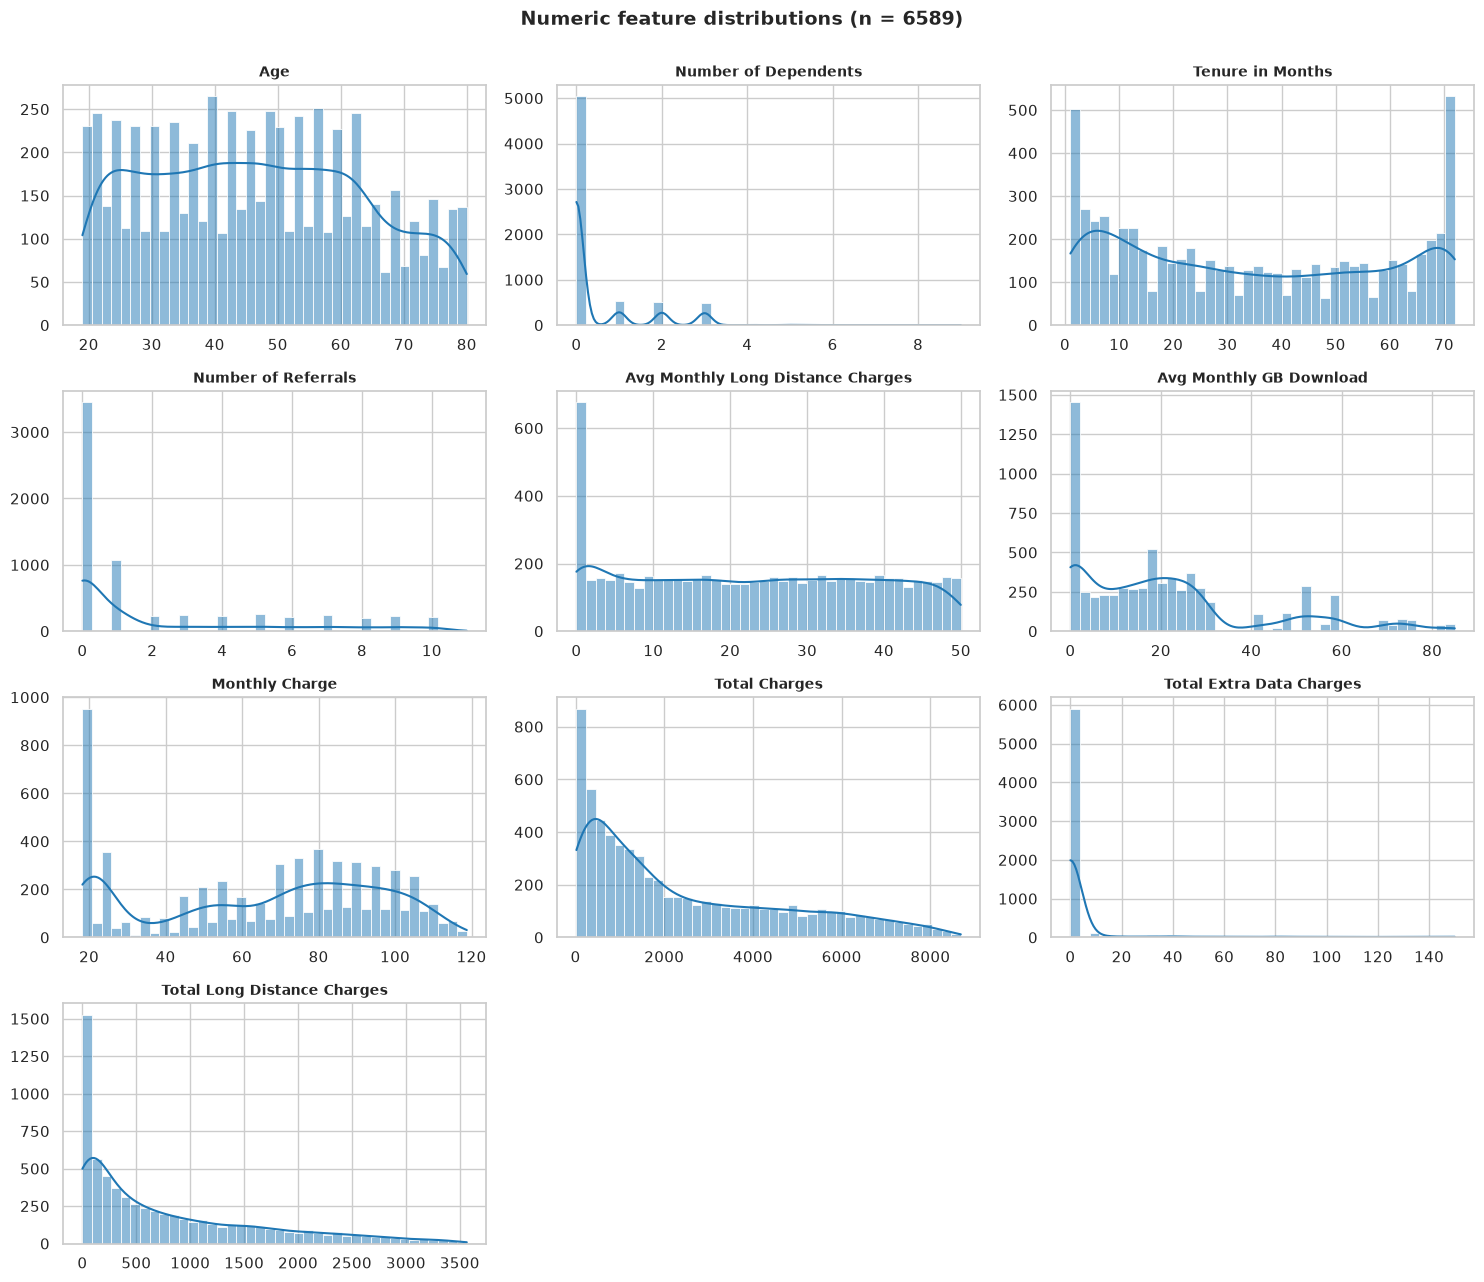

In [13]:
# --- Numeric feature distributions ---
n_cols = 3
n_rows = int(np.ceil(len(NUMERIC_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.2 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(df_no_joined[col], bins=40, kde=True, ax=ax, color="#1f77b4")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(NUMERIC_COLS):]:
    ax.axis("off")

fig.suptitle("Numeric feature distributions (n = %d)" % len(df_no_joined),
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()


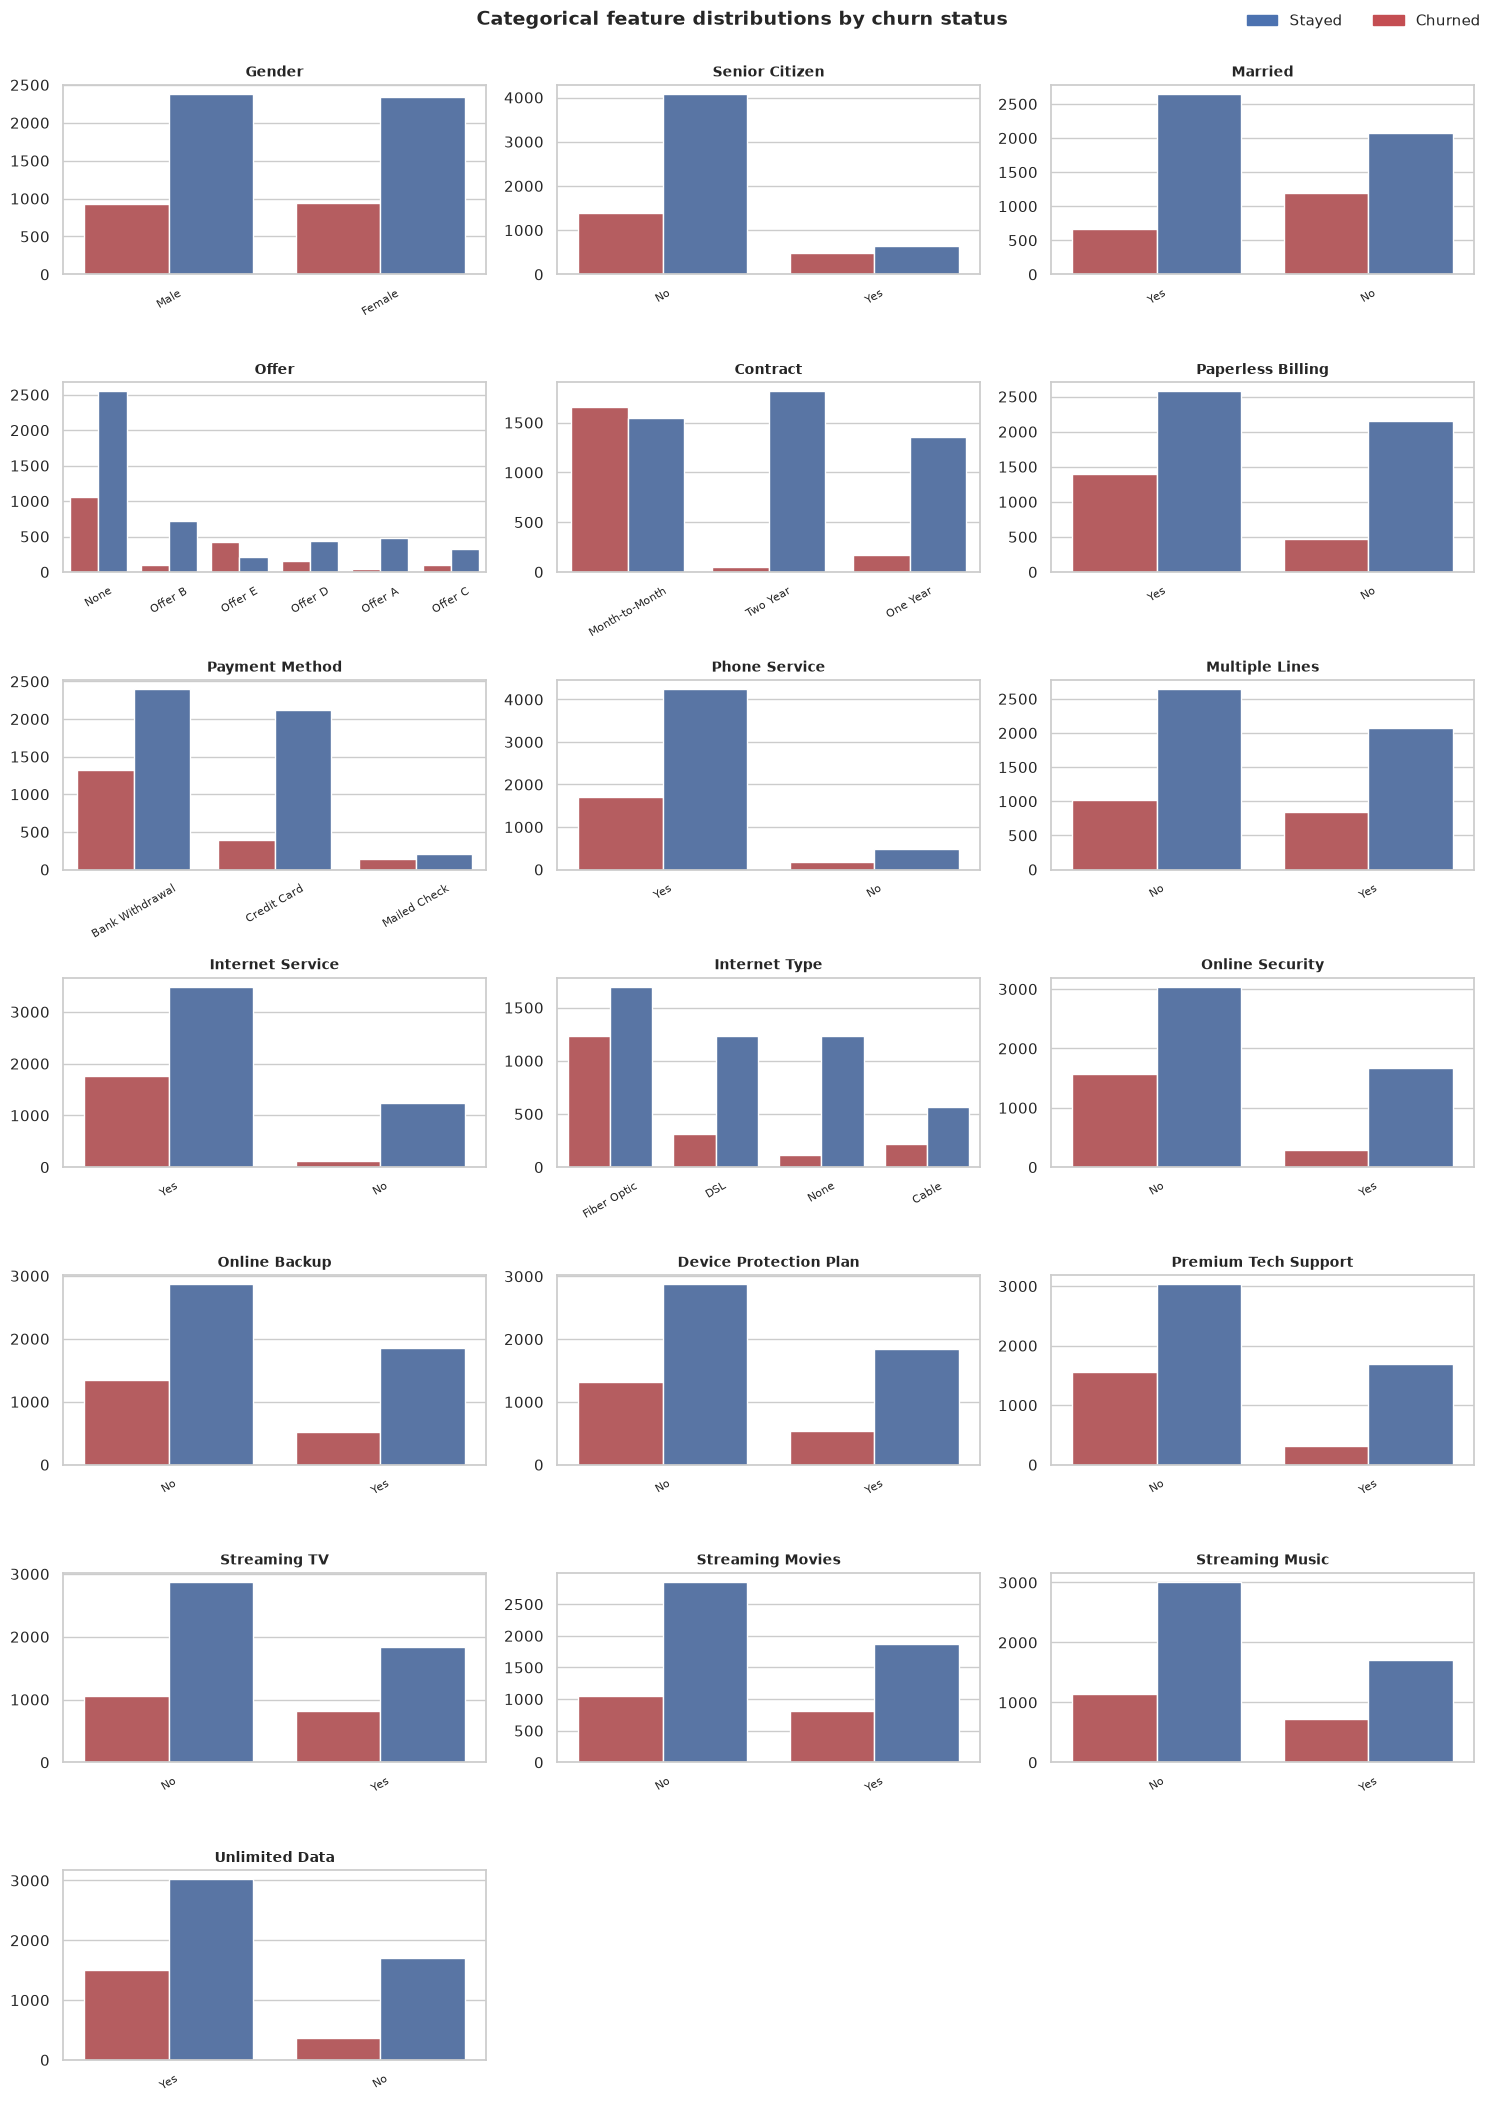

In [14]:
# --- Categorical feature distributions, split by churn ---
n_cols = 3
n_rows = int(np.ceil(len(CATEGORICAL_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.0 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, CATEGORICAL_COLS):
    order = df_no_joined[col].value_counts().index
    sns.countplot(data=df_no_joined, x=col, hue="Churn Label",
                  order=order, ax=ax, palette={"No": "#4c72b0", "Yes": "#c44e52"})
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for ax in axes[len(CATEGORICAL_COLS):]:
    ax.axis("off")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#4c72b0", "#c44e52"]]
fig.legend(handles, ["Stayed", "Churned"], loc="upper right", ncol=2, frameon=False)
fig.suptitle("Categorical feature distributions by churn status",
             fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()


### 4.2 Tương quan giữa các numeric feature (Spearman)

Kiểm tra multicollinearity — đặc biệt `Total Charges` vs `Tenure in Months` vs `Monthly Charge`.


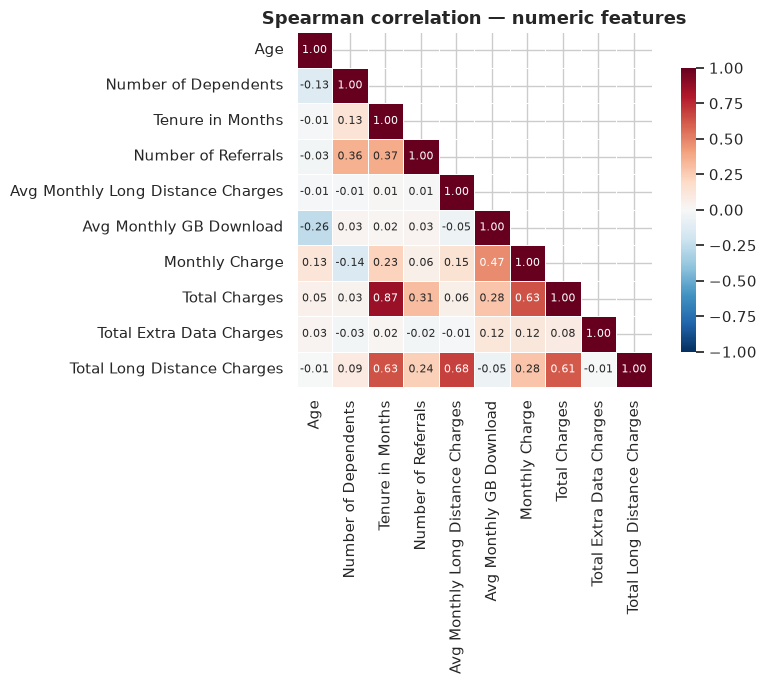

Pairs with |rho| > 0.7: 11


,col_a,col_b,rho
0,Age,Age,1.0000
11,Number of Dependents,Number of Dependents,1.0000
22,Tenure in Months,Tenure in Months,1.0000
33,Number of Referrals,Number of Referrals,1.0000
44,Avg Monthly Long Distance Charges,Avg Monthly Long Distance Charges,1.0000
55,Avg Monthly GB Download,Avg Monthly GB Download,1.0000
66,Monthly Charge,Monthly Charge,1.0000
77,Total Charges,Total Charges,1.0000
88,Total Extra Data Charges,Total Extra Data Charges,1.0000
99,Total Long Distance Charges,Total Long Distance Charges,1.0000


>>> Decision: keep all three billing columns (A). The MLP handles
>>> collinearity; dropping them would discard real signal.


In [15]:
corr = df_no_joined[NUMERIC_COLS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Spearman correlation — numeric features")
plt.tight_layout()
plt.show()

# Flag strong pairs
pairs = (
    corr.where(~mask)
    .stack()
    .reset_index()
    .rename(columns={"level_0": "col_a", "level_1": "col_b", 0: "rho"})
)
strong = pairs[pairs["rho"].abs() > 0.7].sort_values("rho", key=abs, ascending=False)
print(f"Pairs with |rho| > 0.7: {len(strong)}")
if len(strong):
    display(strong)
    print(">>> Decision: keep all three billing columns (A). The MLP handles")
    print(">>> collinearity; dropping them would discard real signal.")


### 4.3 Bảng chốt feature — phủ đủ 50 cột gốc

Mỗi cột gốc phải được phân loại **chính xác một lần**: `feature` / `drop` / `id`.


In [16]:
REASON = {
    # Loại 1
    "Churn Label": "Loại 1 — target leakage (label source)",
    "Customer Status": "Loại 1 — target leakage (3-class source)",
    # Loại 2
    "Churn Score": "Loại 2 — post-hoc; used as E0 external baseline only",
    "CLTV": "Loại 2 — post-hoc predicted lifetime value",
    "Satisfaction Score": "Loại 2 — collected at quarter end, post-decision",
    # Loại 3
    "Total Revenue": "Loại 3 — includes refunds (downstream of complaints)",
    "Total Refunds": "Loại 3 — result of complaints, precursor to churn",
    "Churn Category": "Loại 3 — exit reason; EDA only (E5.2 strata)",
    "Churn Reason": "Loại 3 — exit reason text; EDA only",
    # Loại 4
    "Country": "Loại 4 — constant (United States)",
    "State": "Loại 4 — constant (California)",
    "Quarter": "Loại 4 — constant (Q3)",
    # Loại 5
    "City": "Loại 5 — geo high-cardinality; EDA only",
    "Zip Code": "Loại 5 — geo high-cardinality; EDA only",
    "Latitude": "Loại 5 — geo high-cardinality; EDA only",
    "Longitude": "Loại 5 — geo high-cardinality; EDA only",
    "Population": "Loại 5 — geo high-cardinality; EDA only",
    # Loại 6
    "Under 30": "Loại 6 — derived from Age",
    "Referred a Friend": "Loại 6 — derived from Number of Referrals",
    "Dependents": "Loại 6 — binary form of Number of Dependents",
}

GROUP = {}
for c in DEMOGRAPHIC_COLS:
    GROUP[c] = "Demographics"
for c in ACCOUNT_COLS:
    GROUP[c] = "Account"
for c in SERVICE_COLS:
    GROUP[c] = "Services"
for c in USAGE_BILLING_COLS:
    GROUP[c] = "Usage & Billing"

rows = []
for col in raw.columns:
    if col == ID_COL:
        rows.append({"column": col, "decision": "id", "group": "—",
                     "reason": "identifier only; kept for silo disjointness checks"})
    elif col in FEATURE_COLS:
        rows.append({"column": col, "decision": "FEATURE", "group": GROUP[col],
                     "reason": "valid pre-outcome signal"})
    else:
        rows.append({"column": col, "decision": "drop", "group": "—",
                     "reason": REASON.get(col, "UNCLASSIFIED")})

feature_table = pd.DataFrame(rows)

# --- Coverage assertions ---
assert len(feature_table) == 50, f"table covers {len(feature_table)} columns, expected 50"
assert (feature_table["decision"] == "FEATURE").sum() == 29
assert (feature_table["decision"] == "drop").sum() == 20
assert (feature_table["decision"] == "id").sum() == 1
assert "UNCLASSIFIED" not in feature_table["reason"].values, "some column lacks a reason"

print(f"Total columns : {len(feature_table)}")
print(feature_table["decision"].value_counts().to_string())
print("\n>>> All 50 raw columns classified exactly once.")
display(feature_table)


Total columns : 50
decision
FEATURE    29
drop       20
id          1

>>> All 50 raw columns classified exactly once.


,column,decision,group,reason
0,Customer ID,id,—,identifier only; kept for silo disjointness ch...
1,Gender,FEATURE,Demographics,valid pre-outcome signal
2,Age,FEATURE,Demographics,valid pre-outcome signal
3,Under 30,drop,—,Loại 6 — derived from Age
4,Senior Citizen,FEATURE,Demographics,valid pre-outcome signal
5,Married,FEATURE,Demographics,valid pre-outcome signal
6,Dependents,drop,—,Loại 6 — binary form of Number of Dependents
7,Number of Dependents,FEATURE,Demographics,valid pre-outcome signal
8,Country,drop,—,Loại 4 — constant (United States)
9,State,drop,—,Loại 4 — constant (California)


## 5. Trực quan hóa kết quả

### 5.1 Churn rate theo từng feature quan trọng

So sánh churn rate giữa các nhóm của những feature có tín hiệu mạnh nhất.


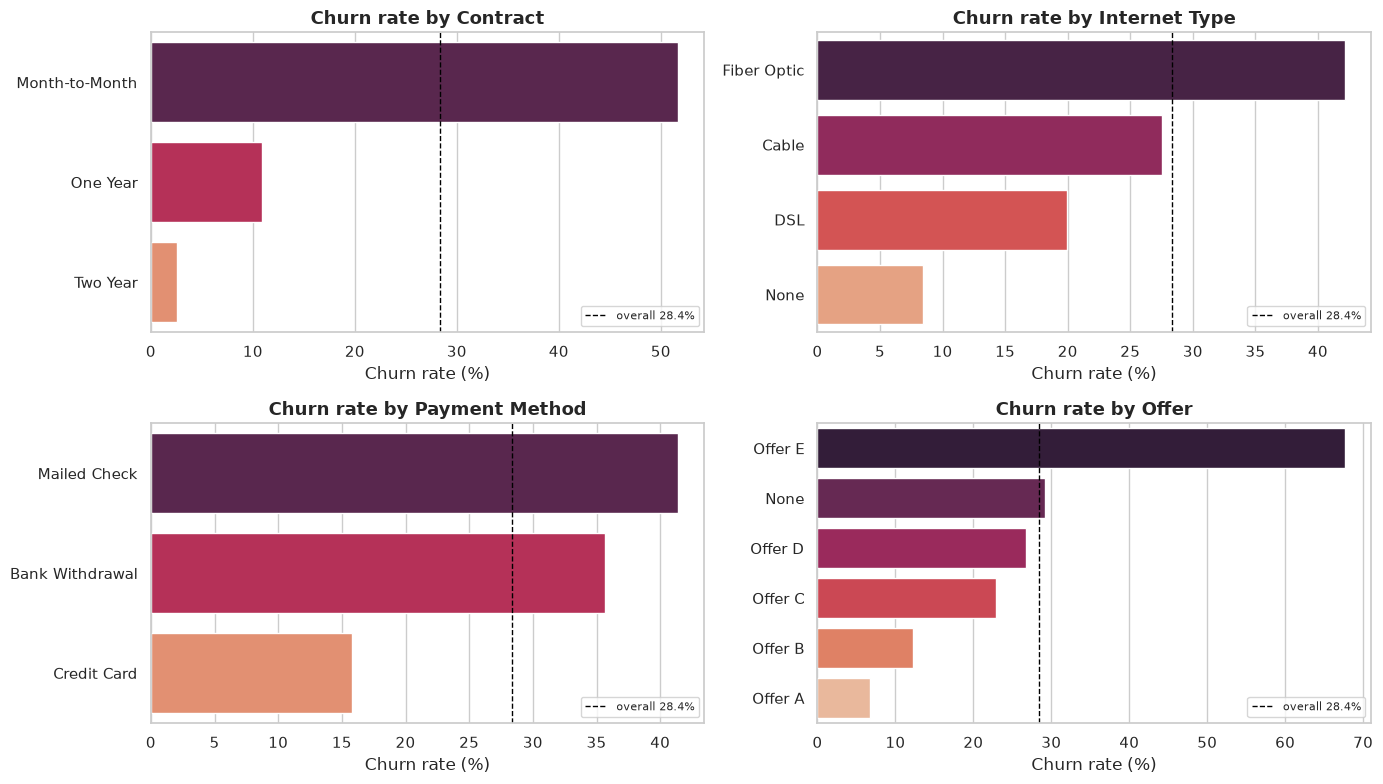

In [17]:
KEY_CATS = ["Contract", "Internet Type", "Payment Method", "Offer"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, KEY_CATS):
    rates = (
        df_no_joined.groupby(col)["Churn Label"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )
    sns.barplot(x=rates.values, y=rates.index, ax=ax, palette="rocket")
    ax.axvline(rate_clean * 100, color="black", linestyle="--", linewidth=1,
               label=f"overall {rate_clean*100:.1f}%")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


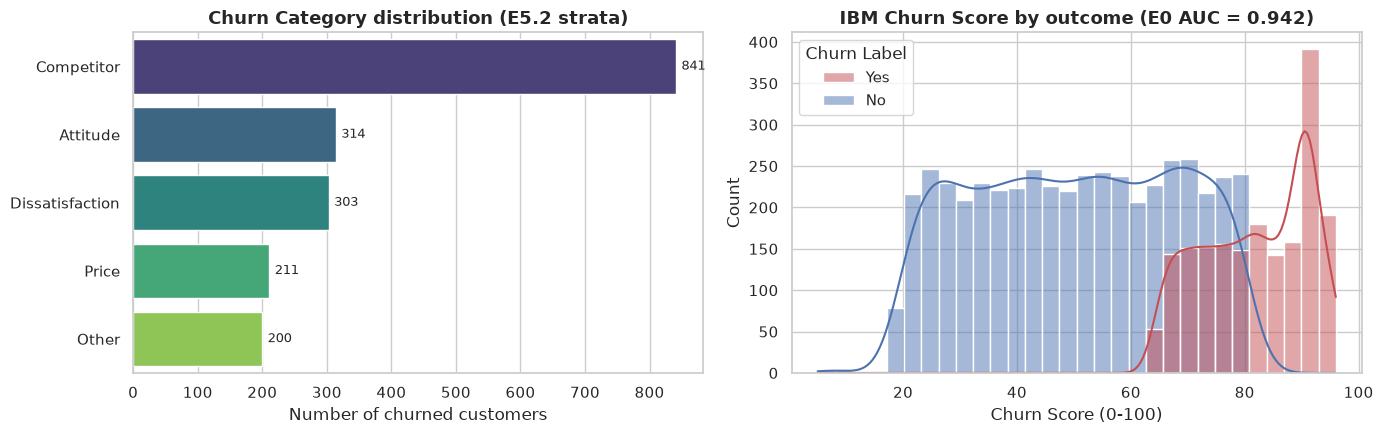

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# --- Churn Category distribution (E5.2 strata) ---
cat_plot = df_no_joined["Churn Category"].value_counts()
sns.barplot(x=cat_plot.values, y=cat_plot.index, ax=axes[0], palette="viridis")
axes[0].set_title("Churn Category distribution (E5.2 strata)")
axes[0].set_xlabel("Number of churned customers")
axes[0].set_ylabel("")
for i, v in enumerate(cat_plot.values):
    axes[0].text(v + max(cat_plot.values) * 0.01, i, f"{v:,}", va="center", fontsize=9)

# --- Churn Score distribution by actual outcome (E0) ---
sns.histplot(data=df_no_joined, x="Churn Score", hue="Churn Label",
             bins=30, kde=True, ax=axes[1], palette={"No": "#4c72b0", "Yes": "#c44e52"})
axes[1].set_title(f"IBM Churn Score by outcome (E0 AUC = {e0_auc:.3f})")
axes[1].set_xlabel("Churn Score (0-100)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


### 5.2 Tóm tắt số liệu then chốt

Bảng tổng hợp mọi con số mà báo cáo sẽ trích dẫn.


In [19]:
summary = pd.DataFrame([
    ("Raw shape", f"{raw.shape[0]:,} x {raw.shape[1]}"),
    ("Joined rows dropped", f"{n_joined:,} ({n_joined/len(raw)*100:.2f}%)"),
    ("Cohort after drop", f"{len(df_no_joined):,}"),
    ("Churn rate (clean cohort)", f"{rate_clean*100:.2f}%"),
    ("Churned / Stayed", f"{int((df_no_joined['Churn Label']=='Yes').sum()):,} / "
                          f"{int((df_no_joined['Churn Label']=='No').sum()):,}"),
    ("Features kept", f"{len(FEATURE_COLS)} (5 demo + 6 account + 12 services + 6 usage)"),
    ("Columns dropped", f"{len(DROPPED_COLS)} (Loại 1-6)"),
    ("E0 — IBM Churn Score AUC", f"{e0_auc:.4f}"),
    ("Churn Category strata", f"{n_strata}"),
    ("Zero-variance columns", f"{len(zero_var)}"),
], columns=["metric", "value"])

display(summary)

print("\n" + "=" * 62)
print("KEY NUMBERS FOR THE REPORT")
print("=" * 62)
for _, r in summary.iterrows():
    print(f"  {r['metric']:<28} {r['value']}")
print("=" * 62)


,metric,value
0,Raw shape,"7,043 x 50"
1,Joined rows dropped,454 (6.45%)
2,Cohort after drop,"6,589"
3,Churn rate (clean cohort),28.37%
4,Churned / Stayed,"1,869 / 4,720"
5,Features kept,29 (5 demo + 6 account + 12 services + 6 usage)
6,Columns dropped,20 (Loại 1-6)
7,E0 — IBM Churn Score AUC,0.9421
8,Churn Category strata,5
9,Zero-variance columns,3



KEY NUMBERS FOR THE REPORT
  Raw shape                    7,043 x 50
  Joined rows dropped          454 (6.45%)
  Cohort after drop            6,589
  Churn rate (clean cohort)    28.37%
  Churned / Stayed             1,869 / 4,720
  Features kept                29 (5 demo + 6 account + 12 services + 6 usage)
  Columns dropped              20 (Loại 1-6)
  E0 — IBM Churn Score AUC     0.9421
  Churn Category strata        5
  Zero-variance columns        3


## 6. Lưu và xuất kết quả

### 6.1 Ghi `eda_7043.parquet` (D0.5)

50 cột gốc, đã bỏ `Joined`, giá trị **nguyên vẹn** — dùng cho EDA, E0 và E5.2.


In [20]:
out_dir = CFG.paths.processed_dir
out_dir.mkdir(parents=True, exist_ok=True)

eda_path = out_dir / CFG.paths.eda_parquet.name
df_no_joined.to_parquet(eda_path, index=False)

print(f"Wrote {eda_path}")
print(f"  shape : {df_no_joined.shape[0]:,} rows x {df_no_joined.shape[1]} cols")
print(f"  size  : {eda_path.stat().st_size / 1024:.1f} KB")

# Round-trip verification
check = pd.read_parquet(eda_path)
assert check.shape == df_no_joined.shape
assert "Joined" not in set(check[STATUS_COL].unique())
print("  round-trip OK — no 'Joined' rows, shape preserved")


Wrote /home/pcn/261/big_data/source/data/processed/eda_7043.parquet
  shape : 6,589 rows x 50 cols
  size  : 451.1 KB
  round-trip OK — no 'Joined' rows, shape preserved


### 6.2 Xuất bảng quyết định feature

Lưu `results/eda_feature_decisions.csv` để `docs/04_data_decisions.md` trích dẫn trực tiếp.


In [21]:
results_dir = CFG.paths.results_dir
results_dir.mkdir(parents=True, exist_ok=True)

# 1. Feature decision table
feat_csv = results_dir / "eda_feature_decisions.csv"
feature_table.to_csv(feat_csv, index=False)
print(f"Wrote {feat_csv} ({len(feature_table)} rows)")

# 2. Leakage audit (E0 numbers)
leak_csv = results_dir / "eda_leakage_audit.csv"
leakage_audit.to_csv(leak_csv)
print(f"Wrote {leak_csv}")

# 3. Key metrics summary
sum_csv = results_dir / "eda_summary.csv"
summary.to_csv(sum_csv, index=False)
print(f"Wrote {sum_csv}")

print("\nAll EDA outputs written to results/")


Wrote /home/pcn/261/big_data/source/results/eda_feature_decisions.csv (50 rows)
Wrote /home/pcn/261/big_data/source/results/eda_leakage_audit.csv
Wrote /home/pcn/261/big_data/source/results/eda_summary.csv

All EDA outputs written to results/


## 7. Kết luận & bàn giao cho W2

### Đã chốt

| Quyết định | Giá trị |
|---|---|
| Cohort huấn luyện | Bỏ `Joined` **trước** amplification |
| Số feature | **29** (5 + 6 + 12 + 6) |
| `clean_7043.parquet` | 31 cột = `Customer ID` + 29 features + `churn` |
| `eda_7043.parquet` | 50 cột, giữ leakage cho EDA/E0/E5.2 |
| `Churn Score` | **E0 external baseline**, không bao giờ là feature |
| Billing columns | Giữ cả 3 (A) — MLP tự xử lý collinearity |
| `Offer = "None"` | Giữ làm category riêng (A) |

### Bàn giao

- **W2 (Amplification):** dùng `clean_7043.parquet` (29 features + target), **không** amplify 50 cột.
- **E0:** dùng `e0_auc` đo được ở §3.5 làm mốc tham chiếu.
- **E5.2:** dùng `Churn Category` từ `eda_7043.parquet` để stratify.

### Cảnh báo đã xử lý trong pipeline

1. Header lỗi `"Total Refu    nds"` → sửa thành `Total Refunds` (nếu không, cột này sẽ lọt vào feature matrix).
2. `"None"` là category hợp lệ của `Offer` / `Internet Type` → phải đọc với `keep_default_na=False`.
